In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rain2loss.evt import (annual_maxima, block_bootstrap_years, bootstrap_return_levels,
                           empirical_return_periods, fit_gev_lmom, fit_gev_mle, return_level,
                           return_period, scale_largest_storm)
from rain2loss.hbv import run_hbv
from rain2loss.lamah import load_attributes, load_hbv_inputs
from rain2loss.paths import RESULTS

GAUGE_ID = 824
attrs = load_attributes()
to_m3s = attrs.loc[GAUGE_ID, "area_gov"] / 86.4
data = load_hbv_inputs(GAUGE_ID, attrs).loc[:"2017-12-31"]
q_obs = data["qobs"] * to_m3s                              # m3/s from here on
saved = json.loads((RESULTS / "hbv_params_824.json").read_text())
params, zones = saved["params"], saved["zones"]

In [2]:
ams = annual_maxima(q_obs)
print(len(ams), "years")
print(ams.sort_values("peak", ascending=False).head(5).round({"peak": 1}))
print(ams["date"].dt.month.value_counts().sort_index())

36 years
       peak       date
1997  258.0 1997-07-07
2011   72.9 2011-07-22
2000   59.8 2000-03-10
2006   54.6 2006-04-03
2002   43.8 2002-02-13
date
1     3
2     4
3     9
4     8
5     2
7     4
8     1
9     3
11    2
Name: count, dtype: int64


In [3]:
T = [2, 5, 10, 20, 50, 100, 200, 500, 1000]
gev_lmom = fit_gev_lmom(ams["peak"])
gev_mle = fit_gev_mle(ams["peak"])
print("L-moments: c = %.3f (xi = %.3f), loc = %.1f, scale = %.1f" % (gev_lmom[0], -gev_lmom[0], gev_lmom[1], gev_lmom[2]))
print("MLE      : c = %.3f (xi = %.3f), loc = %.1f, scale = %.1f" % (gev_mle[0], -gev_mle[0], gev_mle[1], gev_mle[2]))
boot = bootstrap_return_levels(ams["peak"], T, n_boot=1000)
freq = pd.DataFrame({"T": T, "Q_lmom": return_level(gev_lmom, T), "Q_mle": return_level(gev_mle, T),
                     "lmom_5%": boot.quantile(0.05).to_numpy(), "lmom_95%": boot.quantile(0.95).to_numpy()})
freq.to_csv(RESULTS / "flood_frequency_824.csv", index=False)
freq.round(0)

L-moments: c = -0.528 (xi = 0.528), loc = 24.8, scale = 8.1
MLE      : c = -0.394 (xi = 0.394), loc = 25.4, scale = 9.2


,T,Q_lmom,Q_mle,lmom_5%,lmom_95%
0,2,28.0,29.0,26.0,33.0
1,5,43.0,44.0,36.0,54.0
2,10,60.0,59.0,43.0,80.0
3,20,83.0,78.0,48.0,122.0
4,50,130.0,111.0,54.0,215.0
5,100,183.0,146.0,58.0,330.0
6,200,260.0,191.0,62.0,507.0
7,500,417.0,273.0,67.0,899.0
8,1000,597.0,359.0,70.0,1400.0


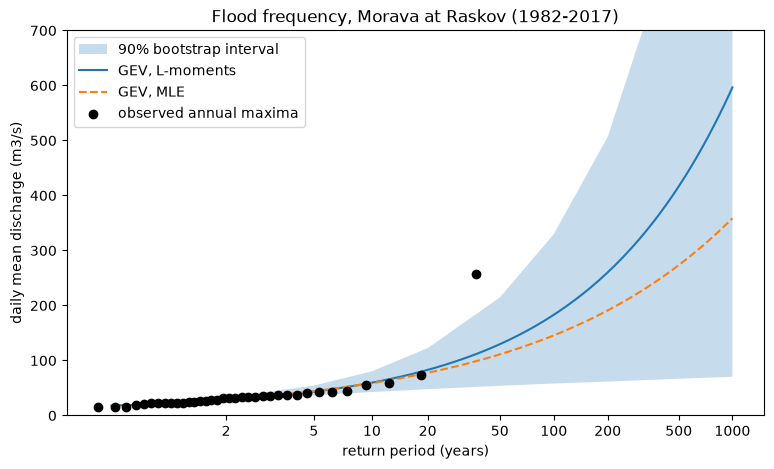

In [4]:
def gumbel_axis(T):
    """Gumbel reduced variate: a Gumbel distribution plots as a straight line."""
    return -np.log(-np.log(1 - 1 / np.asarray(T, dtype=float)))


T_line = np.logspace(np.log10(1.05), 3, 200)
ticks = [2, 5, 10, 20, 50, 100, 200, 500, 1000]
fig, ax = plt.subplots(figsize=(9, 5))
ax.fill_between(gumbel_axis(T), freq["lmom_5%"], freq["lmom_95%"], alpha=0.25, label="90% bootstrap interval")
ax.plot(gumbel_axis(T_line), return_level(gev_lmom, T_line), label="GEV, L-moments")
ax.plot(gumbel_axis(T_line), return_level(gev_mle, T_line), "--", label="GEV, MLE")
ax.scatter(gumbel_axis(empirical_return_periods(ams["peak"])), ams["peak"], color="black", zorder=3,
           label="observed annual maxima")
ax.set_xticks(gumbel_axis(ticks))
ax.set_xticklabels(ticks)
ax.set(xlabel="return period (years)", ylabel="daily mean discharge (m3/s)", ylim=(0, 700),
       title="Flood frequency, Morava at Raskov (1982-2017)")
ax.legend()
plt.show()

In [5]:
for q in [258.0, 340.0]:
    print(f"{q:.0f} m3/s -> T = {return_period(gev_lmom, q):.0f} yr (L-moments), "
          f"{return_period(gev_mle, q):.0f} yr (MLE)")
without_1997 = fit_gev_lmom(ams.drop(index=1997)["peak"])
print("without 1997: Q100 = %.0f m3/s, T(258 m3/s) = %.0f yr"
      % (return_level(without_1997, [100])[0], return_period(without_1997, 258)))
print("P(at least one 100-year flood in 30 years) = %.2f" % (1 - (1 - 1 / 100) ** 30))

258 m3/s -> T = 197 yr (L-moments), 432 yr (MLE)
340 m3/s -> T = 337 yr (L-moments), 873 yr (MLE)
without 1997: Q100 = 76 m3/s, T(258 m3/s) = 1181064 yr
P(at least one 100-year flood in 30 years) = 0.26


In [6]:
q_sim = run_hbv(data, params, zones)["q_sim"] * to_m3s
ams_sim = annual_maxima(q_sim.loc["1981-11-01":"2017-10-31"])
gev_sim = fit_gev_lmom(ams_sim["peak"])
pd.DataFrame({"T": T, "observed": return_level(gev_lmom, T),
              "simulated": return_level(gev_sim, T)}).round(0)

,T,observed,simulated
0,2,28.0,29.0
1,5,43.0,43.0
2,10,60.0,59.0
3,20,83.0,80.0
4,50,130.0,121.0
5,100,183.0,166.0
6,200,260.0,230.0
7,500,417.0,355.0
8,1000,597.0,495.0


In [7]:
forcing = data[["prec", "temp", "pet"]]
synthetic = block_bootstrap_years(forcing, n_years=1000, seed=1)
synthetic["q"] = run_hbv(synthetic, params, zones)["q_sim"].to_numpy() * to_m3s
events = (synthetic[synthetic["syn_year"] > 1]
          .groupby("syn_year")
          .agg(peak_m3s=("q", "max"), source_year=("source_year", "first")))
events["return_period"] = empirical_return_periods(events["peak_m3s"])
events = events.sort_values("return_period", ascending=False)
print("times the 1997 year was drawn:", int((events["source_year"] == 1997).sum()))
events.head(8).round(1)

times the 1997 year was drawn: 28


,peak_m3s,source_year,return_period
syn_year,,,
550,170.3,1997,1000.0
769,170.3,1997,500.0
65,170.3,1997,333.3
597,170.3,1997,250.0
61,170.3,1997,200.0
864,170.3,1997,166.7
964,170.3,1997,142.9
610,170.3,1997,125.0


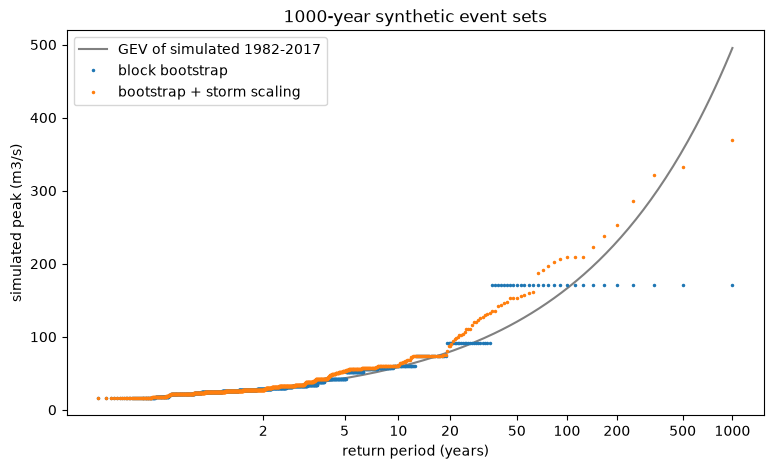

In [8]:
scaled, factors = scale_largest_storm(synthetic, window=5, sigma=0.2, seed=2)
scaled["q"] = run_hbv(scaled, params, zones)["q_sim"].to_numpy() * to_m3s
events_scaled = scaled[scaled["syn_year"] > 1].groupby("syn_year").agg(peak_m3s=("q", "max"))
events_scaled["return_period"] = empirical_return_periods(events_scaled["peak_m3s"])

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(gumbel_axis(T_line), return_level(gev_sim, T_line), color="grey", label="GEV of simulated 1982-2017")
for name, ev in [("block bootstrap", events), ("bootstrap + storm scaling", events_scaled)]:
    ev = ev.sort_values("return_period")
    ax.plot(gumbel_axis(ev["return_period"]), ev["peak_m3s"], ".", markersize=3, label=name)
ax.set_xticks(gumbel_axis(ticks))
ax.set_xticklabels(ticks)
ax.set(xlabel="return period (years)", ylabel="simulated peak (m3/s)", title="1000-year synthetic event sets")
ax.legend()
plt.show()

events.to_csv(RESULTS / "event_set_824.csv")
events_scaled.to_csv(RESULTS / "event_set_scaled_824.csv")